This project is done by:
Bin Huang
8391865

**Declaration of GenAI Use:**

GenAI tools like Claude and Gemini were used during this project.

First, they were used to help draft and proofread the prose of this report. All technical content, figures, tables, numerical results, conclusions, critical thinking & decision making are my own. Every line was reviewed and edited by me.

Second, AI tools assisted with generating repetitive code in this notebook (for example, the standard PyTorch training loop, the DataLoader setup, and the attention-rollout helper function). I verified, adapted, and tested all generated code against my own data and corrected errors.

Third, AI tools were used to debug and fix runtime errors (for example, the Hugging Face eager-attention setting and the OpenCV float16-to-float32 type conversion). The fixes were implemented and validated by me.


Initiating Libs and Dataset

In [13]:
#[My API Key to access Kaggle is redacted, make sure your kaggle.json credentials are uploaded before running the notebook]

In [14]:
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset
!unzip -q brain-tumor-mri-dataset.zip -d brain_tumor_dataset

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
brain-tumor-mri-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace brain_tumor_dataset/Testing/glioma/Te-gl_1.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace brain_tumor_dataset/Testing/glioma/Te-gl_10.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace brain_tumor_dataset/Testing/glioma/Te-gl_100.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: N


In [15]:
import os

dataset_path = 'brain_tumor_dataset'

for split in ['Training', 'Testing']:
    split_path = os.path.join(dataset_path, split)
    if os.path.exists(split_path):
        print(f"\nDirectory: {split}")
        for class_name in sorted(os.listdir(split_path)):
            class_path = os.path.join(split_path, class_name)
            if os.path.isdir(class_path):
                num_images = len(os.listdir(class_path))
                print(f"  {class_name}: {num_images} images")
    else:
        print(f"Directory not found: {split_path}")


Directory: Training
  glioma: 1400 images
  meningioma: 1400 images
  notumor: 1400 images
  pituitary: 1400 images

Directory: Testing
  glioma: 400 images
  meningioma: 400 images
  notumor: 400 images
  pituitary: 400 images


Import and set-up

In [16]:
import os
import json
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from torchvision import transforms

dataset_path = 'brain_tumor_dataset'
all_filepaths = []
all_labels = []

Pool the images together

In [17]:
# Combine both Kaggle directories into a single pool
for split_dir in ['Training', 'Testing']:
    split_path = os.path.join(dataset_path, split_dir)
    if os.path.exists(split_path):
        for class_name in sorted(os.listdir(split_path)):
            class_path = os.path.join(split_path, class_name)
            if os.path.isdir(class_path):
                for img_name in os.listdir(class_path):
                    all_filepaths.append(os.path.join(class_path, img_name))
                    all_labels.append(class_name)
print(f"Total images pooled: {len(all_filepaths)}")

Total images pooled: 7200


Stratified 80/10/10 Split

In [18]:
SEED = 42
X_train, X_temp, y_train, y_temp = train_test_split(
    all_filepaths, all_labels, test_size=0.20, stratify=all_labels, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
print(f"Train size: {len(X_train)} | Val size: {len(X_val)} | Test size: {len(X_test)}")

Train size: 5760 | Val size: 720 | Test size: 720


Plot training distribution

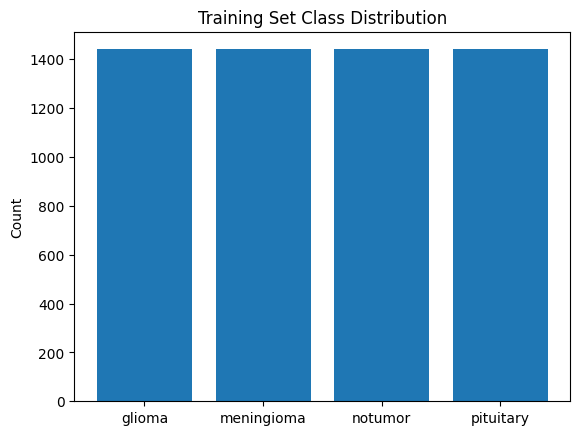

In [19]:
train_counts = Counter(y_train)
plt.bar(train_counts.keys(), train_counts.values())
plt.title('Training Set Class Distribution')
plt.ylabel('Count')
plt.show()

Save the split indices

In [20]:
# Save split dictionary for reproducibility
splits = {
    'train': X_train,
    'val': X_val,
    'test': X_test
}
with open('dataset_splits.json', 'w') as f:
    json.dump(splits, f)
print("dataset_splits.json saved successfully.")

dataset_splits.json saved successfully.


Define transform pipelines

In [21]:
# ImageNet statistics for normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
IMAGE_SIZE = 224

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])
print("Transforms defined successfully.")

Transforms defined successfully.


I used a stratified split to make sure our training, validation, and test sets all have the exact same mix of tumor types. For the images, I resized them to 224x224 because our chosen pre-trained models require this specific size to work. I also added slight rotations and horizontal flips to simulate different patient positions in the MRI scanner. This gives the model more variety to learn from, and to prevent it from just memorizing the training data, without changing what a real brain MRI should look like. Basically I'm preventing overfitting

In [22]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

class BrainTumorDataset(Dataset):
    def __init__(self, filepaths, transform=None):
        self.filepaths = filepaths
        # Extract labels from the folder name directly
        self.label_names = sorted(['glioma', 'meningioma', 'notumor', 'pituitary'])
        self.label_map = {name: i for i, name in enumerate(self.label_names)}
        self.labels = [self.label_map[os.path.basename(os.path.dirname(path))] for path in filepaths]
        self.transform = transform

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        img_path = self.filepaths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

# Create PyTorch datasets using the splits from Step 2
train_dataset = BrainTumorDataset(splits['train'], transform=train_transforms)
val_dataset = BrainTumorDataset(splits['val'], transform=eval_transforms)
test_dataset = BrainTumorDataset(splits['test'], transform=eval_transforms)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("DataLoaders ready.")

DataLoaders ready.


In [23]:
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim
import torch

# This should now print: Using device: cuda
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
num_ftrs = resnet.fc.in_features
resnet.fc = nn.Linear(num_ftrs, 4)
resnet = resnet.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(resnet.parameters(), lr=1e-4, weight_decay=1e-2)
scaler = torch.amp.GradScaler('cuda') # Updated to fix the warning

print("Model and optimizer configured.")

Using device: cuda
Model and optimizer configured.


In [24]:

import copy
from tqdm import tqdm

EPOCHS = 10
best_val_acc = 0.0
best_epoch = 0
patience = 3
patience_counter = 0

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):
    # Training Phase
    resnet.train()
    running_loss, running_corrects = 0.0, 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")
    for inputs, labels in train_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.amp.autocast('cuda'):
            outputs = resnet(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == labels.data)
        train_bar.set_postfix(loss=loss.item())

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = running_corrects.double() / len(train_dataset)
    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc.item())

    # Validation Phase
    resnet.eval()
    val_loss, val_corrects = 0.0, 0

    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]")
    with torch.no_grad():
        for inputs, labels in val_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = resnet(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_corrects += torch.sum(preds == labels.data)

    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = val_corrects.double() / len(val_dataset)
    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc.item())

    print(f"\nEpoch {epoch+1}/{EPOCHS} Summary | Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}\n")

    # Early Stopping Logic
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        best_epoch = epoch + 1
        torch.save(resnet.state_dict(), 'resnet50_best.pth')
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("Early stopping triggered.")
        break

print(f"Best Validation Accuracy: {best_val_acc:.4f} at Epoch {best_epoch}")

Epoch 1/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  6.55it/s]



Epoch 1/10 Summary | Train Loss: 0.2752 Acc: 0.9040 | Val Loss: 0.1683 Acc: 0.9514



Epoch 2/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  6.52it/s]



Epoch 2/10 Summary | Train Loss: 0.1077 Acc: 0.9649 | Val Loss: 0.1063 Acc: 0.9597



Epoch 3/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  6.49it/s]


...


Epoch 7/10 Summary | Train Loss: 0.0361 Acc: 0.9882 | Val Loss: 0.1038 Acc: 0.9806



Epoch 8/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  6.51it/s]



Epoch 8/10 Summary | Train Loss: 0.0432 Acc: 0.9870 | Val Loss: 0.0637 Acc: 0.9806



Epoch 9/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  6.41it/s]


Epoch 9/10 Summary | Train Loss: 0.0327 Acc: 0.9882 | Val Loss: 0.1134 Acc: 0.9736

Early stopping triggered.
Best Validation Accuracy: 0.9847 at Epoch 6


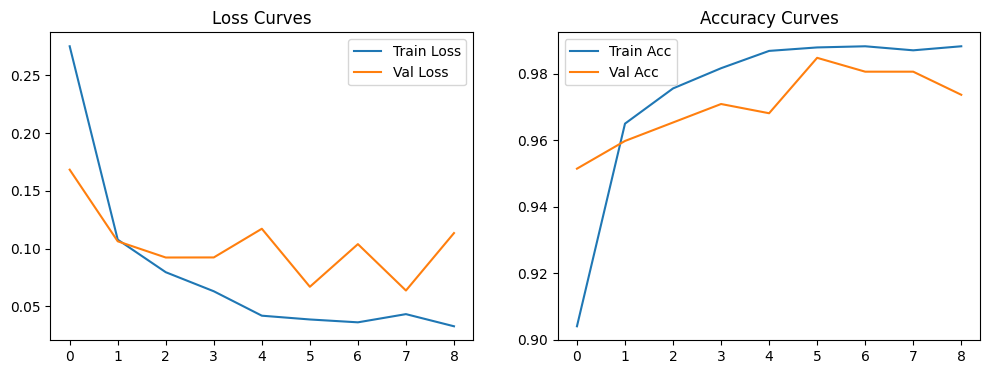

Best model weights successfully reloaded.


In [25]:
import matplotlib.pyplot as plt

# Plotting
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.legend()
plt.title('Loss Curves')

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.legend()
plt.title('Accuracy Curves')
plt.show()

# Verify checkpoint reloads safely
resnet.load_state_dict(torch.load('resnet50_best.pth'))
resnet.eval()
print("Best model weights successfully reloaded.")

Installing Transformers, Loading ViT, and Configuring Optimizer

In [26]:
!pip install -q transformers
import torch
import torch.nn as nn
import torch.optim as optim
from transformers import ViTForImageClassification
from torch.optim.lr_scheduler import StepLR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load ViT pre-trained on ImageNet-21k, configure for 4 classes
# Some weights (like the pre-trained classification head) will be randomly initialized, which is expected.
vit = ViTForImageClassification.from_pretrained(
    'google/vit-base-patch16-224-in21k',
    num_labels=4,
    ignore_mismatched_sizes=True
)
vit = vit.to(device)

# Vision Transformers require a much smaller learning rate than CNNs
optimizer = optim.AdamW(vit.parameters(), lr=2e-5, weight_decay=1e-2)
# StepLR drops the learning rate by half every 3 epochs to help it settle
scheduler = StepLR(optimizer, step_size=3, gamma=0.5)
scaler = torch.amp.GradScaler('cuda')
criterion = nn.CrossEntropyLoss()

print("ViT model and optimizer configured.")

Using device: cuda


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ViT model and optimizer configured.


ViT Training Loop

In [27]:
import copy
from tqdm import tqdm

EPOCHS = 10
best_val_acc = 0.0
best_epoch = 0
patience = 3
patience_counter = 0

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):
    # Training Phase
    vit.train()
    running_loss, running_corrects = 0.0, 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")
    for inputs, labels in train_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.amp.autocast('cuda'):
            # HF Transformers expects 'pixel_values' and returns a struct containing logits
            outputs = vit(pixel_values=inputs)
            logits = outputs.logits
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(logits, 1)
        running_corrects += torch.sum(preds == labels.data)
        train_bar.set_postfix(loss=loss.item())

    scheduler.step() # Update learning rate at end of epoch

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = running_corrects.double() / len(train_dataset)
    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc.item())

    # Validation Phase
    vit.eval()
    val_loss, val_corrects = 0.0, 0

    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]")
    with torch.no_grad():
        for inputs, labels in val_bar:
            inputs, labels = inputs.to(device), labels.to(device)

            with torch.amp.autocast('cuda'):
                outputs = vit(pixel_values=inputs)
                logits = outputs.logits
                loss = criterion(logits, labels)

            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(logits, 1)
            val_corrects += torch.sum(preds == labels.data)

    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = val_corrects.double() / len(val_dataset)
    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc.item())

    print(f"\nEpoch {epoch+1}/{EPOCHS} Summary | Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}\n")

    # Early Stopping Logic
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        best_epoch = epoch + 1
        torch.save(vit.state_dict(), 'vit_best.pth')
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("Early stopping triggered.")
        break

print(f"Best Validation Accuracy: {best_val_acc:.4f} at Epoch {best_epoch}")

Epoch 1/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  7.03it/s]



Epoch 1/10 Summary | Train Loss: 0.5753 Acc: 0.8665 | Val Loss: 0.2978 Acc: 0.9264



Epoch 2/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  6.99it/s]



Epoch 2/10 Summary | Train Loss: 0.1888 Acc: 0.9608 | Val Loss: 0.1772 Acc: 0.9569



Epoch 3/10 [Val]: 100%|██████████| 23/23 [00:04<00:00,  5.08it/s]


...


Epoch 8/10 Summary | Train Loss: 0.0361 Acc: 0.9957 | Val Loss: 0.0841 Acc: 0.9819



Epoch 9/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  7.00it/s]



Epoch 9/10 Summary | Train Loss: 0.0334 Acc: 0.9965 | Val Loss: 0.0825 Acc: 0.9806



Epoch 10/10 [Val]: 100%|██████████| 23/23 [00:03<00:00,  6.65it/s]



Epoch 10/10 Summary | Train Loss: 0.0282 Acc: 0.9979 | Val Loss: 0.0788 Acc: 0.9778

Best Validation Accuracy: 0.9819 at Epoch 8


Plot ViT Curves and Verify Checkpoint

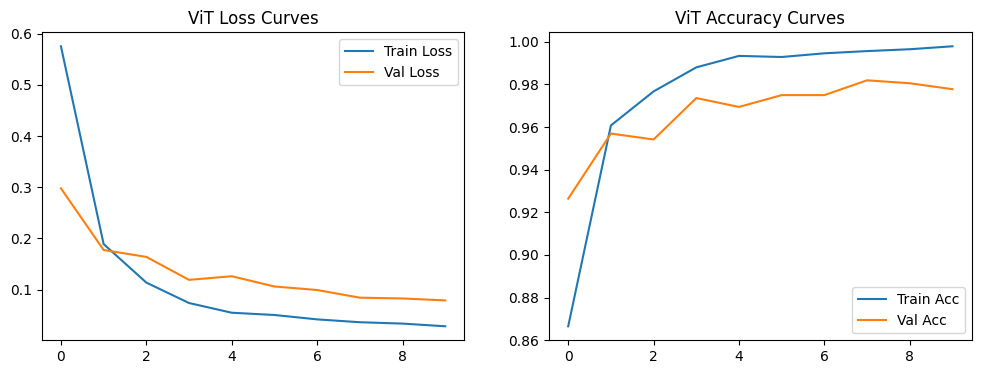

Best ViT model weights successfully reloaded.


In [28]:
import matplotlib.pyplot as plt

# Plotting
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.legend()
plt.title('ViT Loss Curves')

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.legend()
plt.title('ViT Accuracy Curves')
plt.show()

# Verify checkpoint reloads safely
vit.load_state_dict(torch.load('vit_best.pth'))
vit.eval()
print("Best ViT model weights successfully reloaded.")

Save Artefacts and Set Up Reproducibility

In [29]:
from google.colab import drive
import os

# 1. Mount Google Drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

# 2. Create Repository Folder Structure
PROJECT_DIR = '/content/drive/MyDrive/MAAI901_Project'
folders = ['checkpoints', 'notebooks', 'figures', 'src']

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)
print(f"Created project structure at: {PROJECT_DIR}")

# 3. Copy Artefacts to Drive
!cp resnet50_best.pth {PROJECT_DIR}/checkpoints/
!cp vit_best.pth {PROJECT_DIR}/checkpoints/
!cp dataset_splits.json {PROJECT_DIR}/checkpoints/
print("Artefacts successfully copied to Drive.")

# 4. Generate README Skeleton
readme_content = """# MAAI901 Applied Vision Transformer Report

## Project Overview
Fine-tuning a Vision Transformer (ViT-B/16) and ResNet-50 baseline for brain tumor MRI classification.

## Repository Structure
- `notebooks/`: Contains the main Colab execution notebook.
- `checkpoints/`: Model weights and dataset split indices.
- `figures/`: Training curves, confusion matrices, and attention rollouts.
- `src/`: (Optional) Python scripts if refactoring from the notebook.

## Reproducibility
To reproduce this project:
1. Clone the repository.
2. Download the Kaggle dataset `masoudnickparvar/brain-tumor-mri-dataset`.
3. Run the top-to-bottom Colab notebook. The split seed is fixed to 42.
"""

readme_path = os.path.join(PROJECT_DIR, 'README.md')
with open(readme_path, 'w') as f:
    f.write(readme_content)
print(f"README skeleton saved to {readme_path}")

Mounting Google Drive...
Mounted at /content/drive
Created project structure at: /content/drive/MyDrive/MAAI901_Project
Artefacts successfully copied to Drive.
README skeleton saved to /content/drive/MyDrive/MAAI901_Project/README.md


Running test set evaluation...

ResNet-50 Classification Report
              precision    recall  f1-score   support

      glioma     0.9944    0.9778    0.9860       180
  meningioma     0.9617    0.9778    0.9697       180
     notumor     0.9836    1.0000    0.9917       180
   pituitary     0.9944    0.9778    0.9860       180

    accuracy                         0.9833       720
   macro avg     0.9835    0.9833    0.9834       720
weighted avg     0.9835    0.9833    0.9834       720


ViT-B/16 Classification Report
              precision    recall  f1-score   support

      glioma     0.9944    0.9778    0.9860       180
  meningioma     0.9674    0.9889    0.9780       180
     notumor     0.9889    0.9889    0.9889       180
   pituitary     0.9832    0.9778    0.9805       180

    accuracy                         0.9833       720
   macro avg     0.9835    0.9833    0.9834       720
weighted avg     0.9835    0.9833    0.9834       720


Raw Confusion Matrix [ResNet-50]:

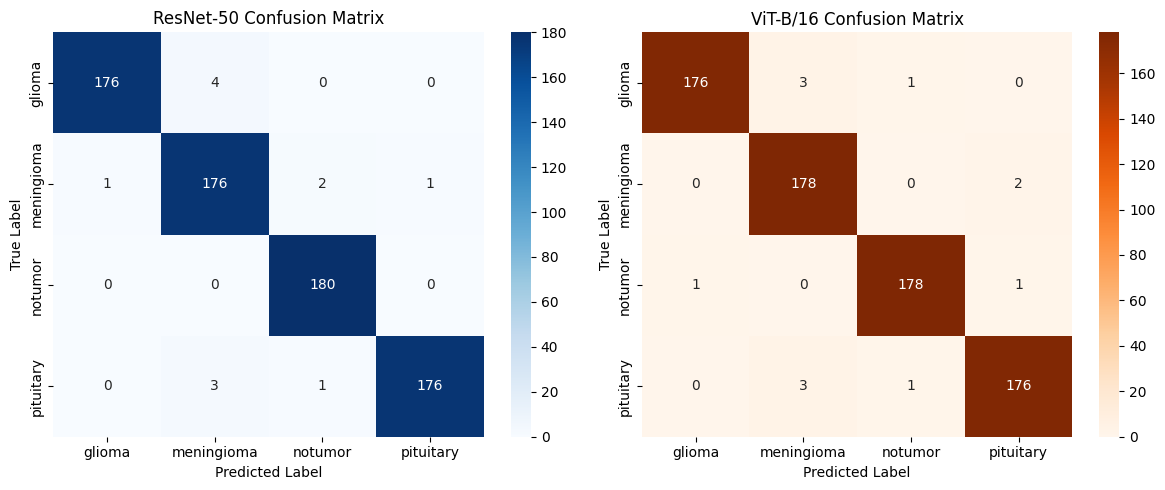


Saved confusion matrices to: /content/drive/MyDrive/MAAI901_Project/figures/confusion_matrices.png


In [30]:
import torch
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Ensure both models are in evaluation mode
resnet.eval()
vit.eval()

true_labels = []
resnet_preds = []
vit_preds = []

print("Running test set evaluation...")

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Ground truth
        true_labels.extend(labels.cpu().numpy())

        with torch.amp.autocast('cuda'):
            # ResNet-50 predictions
            res_outputs = resnet(inputs)
            _, r_preds = torch.max(res_outputs, 1)
            resnet_preds.extend(r_preds.cpu().numpy())

            # ViT-B/16 predictions
            vit_outputs = vit(pixel_values=inputs)
            _, v_preds = torch.max(vit_outputs.logits, 1)
            vit_preds.extend(v_preds.cpu().numpy())

class_names = test_dataset.label_names

# 1. Print Classification Reports
print("\n" + "="*40)
print("ResNet-50 Classification Report")
print("="*40)
print(classification_report(true_labels, resnet_preds, target_names=class_names, digits=4))

print("\n" + "="*40)
print("ViT-B/16 Classification Report")
print("="*40)
print(classification_report(true_labels, vit_preds, target_names=class_names, digits=4))

# 2. Compute Confusion Matrices
res_cm = confusion_matrix(true_labels, resnet_preds)
vit_cm = confusion_matrix(true_labels, vit_preds)

print("\nRaw Confusion Matrix [ResNet-50]:")
print(res_cm)
print("\nRaw Confusion Matrix [ViT-B/16]:")
print(vit_cm)

# 3. Plot and Save Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(res_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('ResNet-50 Confusion Matrix')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(vit_cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('ViT-B/16 Confusion Matrix')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
fig_path = '/content/drive/MyDrive/MAAI901_Project/figures/confusion_matrices.png'
plt.savefig(fig_path, dpi=300)
plt.show()

print(f"\nSaved confusion matrices to: {fig_path}")

Both models achieved an identical macro-F1 score of 0.9834, but overall accuracy is not the most appropriate metric for this problem. In a clinical diagnostic setting, maximizing recall (sensitivity) is critical because a false negative, predicting 'no tumor' for a patient who actually has one, carries severe health risks. In contrast, a false positive typically only results in further screening. When evaluating the confusion matrices for these high-risk errors, ResNet-50 produced 3 critical false negatives (missing 2 meningiomas and 1 pituitary tumor), whereas the ViT-B/16 was slightly safer, producing only 2 false negatives. Aside from these critical misses, both models most frequently misclassified other tumor types as meningiomas, indicating that the decision boundary for the meningioma class is the most visually ambiguous.

In [35]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import ViTForImageClassification

# 1. Reload the architecture explicitly requesting 'eager' attention
vit = ViTForImageClassification.from_pretrained(
    'google/vit-base-patch16-224-in21k',
    num_labels=4,
    ignore_mismatched_sizes=True,
    attn_implementation="eager"
)

# 2. Load your fine-tuned weights back in
vit.load_state_dict(torch.load('vit_best.pth'))
vit = vit.to(device)

# 3. Now we can safely request attentions
vit.config.output_attentions = True
vit.eval()

def compute_rollout(attentions):
    """
    Computes Attention Rollout across all 12 layers of the ViT.
    attentions: tuple of 12 tensors, each shape (batch, heads, 197, 197)
    """
    batch_size = attentions[0].size(0)
    dtype = attentions[0].dtype # Grab the exact data type (float16/Half)

    # Start with an identity matrix matching the dtype
    result = torch.eye(attentions[0].size(-1), device=device, dtype=dtype).unsqueeze(0).repeat(batch_size, 1, 1)

    for attention in attentions:
        # Average attention across all 12 heads in this layer
        attention_heads_fused = attention.mean(axis=1)
        # Add residual connection (identity matrix) matching the dtype
        attention_heads_fused += torch.eye(attention_heads_fused.size(-1), device=device, dtype=dtype)
        # Normalize
        attention_heads_fused = attention_heads_fused / attention_heads_fused.sum(dim=-1, keepdim=True)
        # Matrix multiply with the accumulated rollout
        result = torch.bmm(attention_heads_fused, result)

    # Extract the CLS token's attention to all 196 image patches (index 1 to end)
    mask = result[:, 0, 1:]
    # Reshape the 196 patches back into a 14x14 grid
    mask = mask.reshape(batch_size, 14, 14).detach().cpu().numpy()

    # Normalize the mask for visualization (0 to 1)
    mask = mask / np.max(mask, axis=(1, 2), keepdims=True)
    return mask

print("ViT reloaded with eager attention and rollout function updated for mixed precision.")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ViT reloaded with eager attention and rollout function updated for mixed precision.


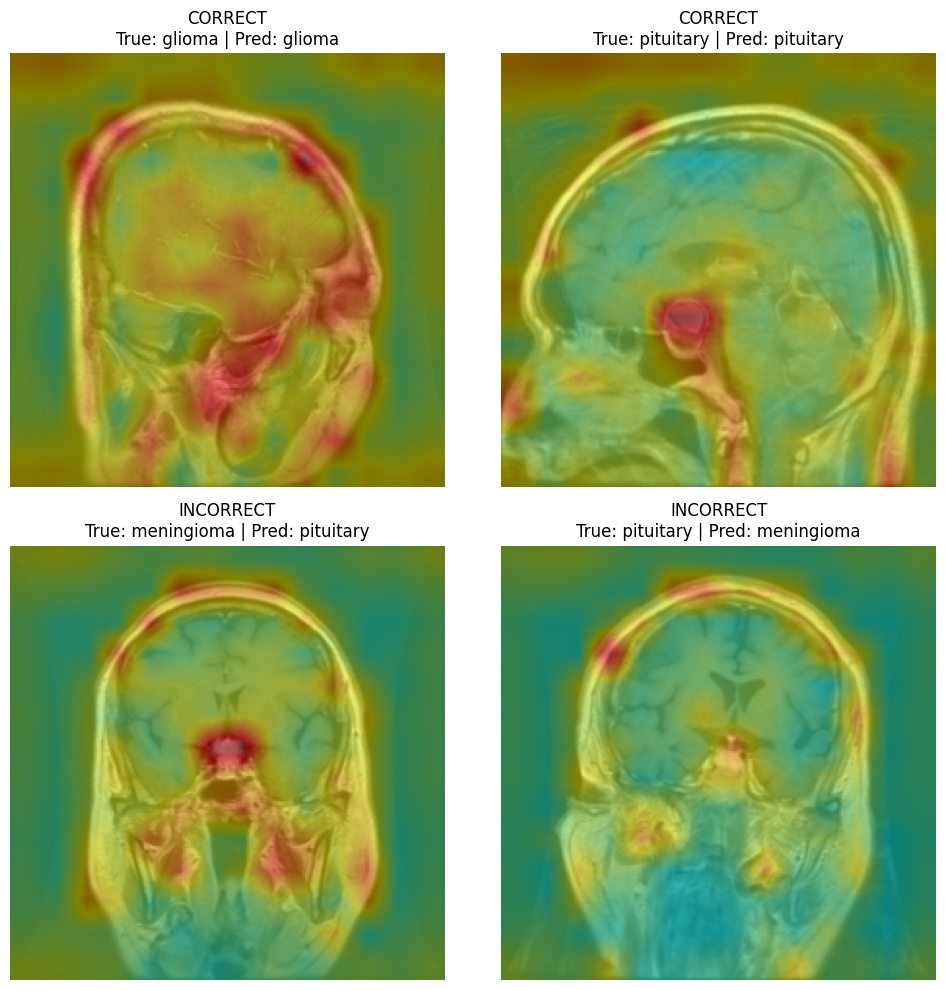

Saved attention rollouts to /content/drive/MyDrive/MAAI901_Project/figures/attention_rollout.png


In [37]:
# We will collect 2 correct and 2 incorrect predictions
correct_samples = []
incorrect_samples = []

# Un-normalize function for plotting the original image
def unnormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(device)
    tensor = tensor * std + mean
    return tensor.cpu().numpy().transpose(1, 2, 0)

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        with torch.amp.autocast('cuda'):
            outputs = vit(pixel_values=inputs)
            logits = outputs.logits
            attentions = outputs.attentions

        _, preds = torch.max(logits, 1)
        masks = compute_rollout(attentions)

        for i in range(inputs.size(0)):
            is_correct = (preds[i] == labels[i]).item()
            sample_data = {
                'image': inputs[i],
                'mask': masks[i],
                'true_label': test_dataset.label_names[labels[i].item()],
                'pred_label': test_dataset.label_names[preds[i].item()]
            }

            if is_correct and len(correct_samples) < 5: # Grab 5 to find a good one
                correct_samples.append(sample_data)
            elif not is_correct and len(incorrect_samples) < 5:
                incorrect_samples.append(sample_data)

        if len(correct_samples) >= 5 and len(incorrect_samples) >= 5:
            break

# Plot 2 correct and 2 incorrect
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
samples_to_plot = correct_samples[:2] + incorrect_samples[:2]

for idx, ax in enumerate(axes.flat):
    sample = samples_to_plot[idx]

    # Process original image
    img = unnormalize(sample['image'])
    img = np.clip(img, 0, 1)

    # Process heatmap
    mask_np = sample['mask'].astype(np.float32) # FIX: convert to float32 for OpenCV
    mask_resized = cv2.resize(mask_np, (224, 224))
    heatmap = cv2.applyColorMap(np.uint8(255 * mask_resized), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    heatmap = heatmap[..., ::-1] # BGR to RGB

    # Overlay
    overlay = 0.5 * img + 0.5 * heatmap

    ax.imshow(overlay)
    status = "CORRECT" if idx < 2 else "INCORRECT"
    ax.set_title(f"{status}\nTrue: {sample['true_label']} | Pred: {sample['pred_label']}")
    ax.axis('off')

plt.tight_layout()
fig_path = '/content/drive/MyDrive/MAAI901_Project/figures/attention_rollout.png'
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved attention rollouts to {fig_path}")

Extracting probabilities on test set...

Calibration Metrics
ResNet-50  | ECE: 0.0100 | Multi-class Brier: 0.0248
ViT-B/16   | ECE: 0.0208 | Multi-class Brier: 0.0263


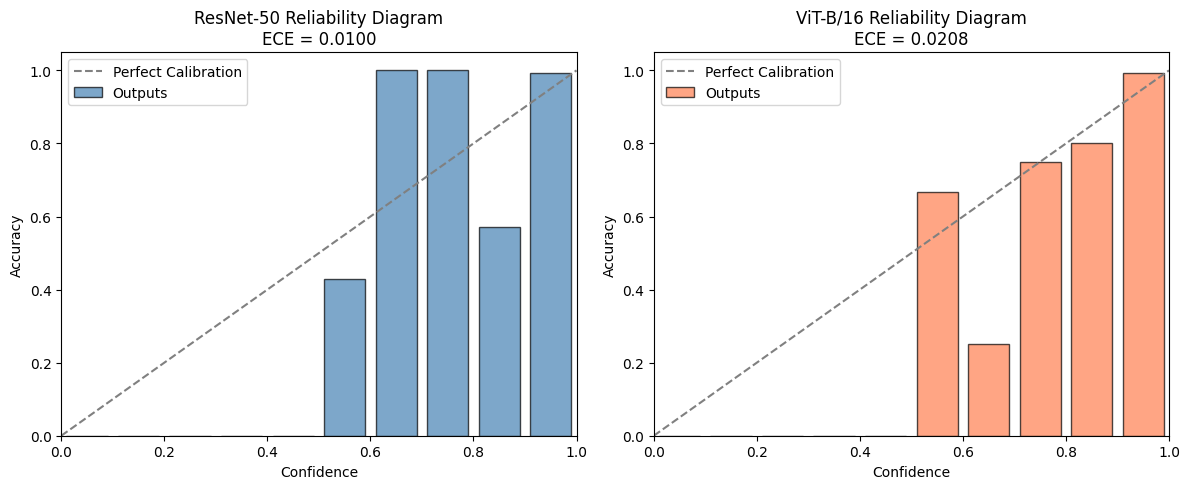

Saved calibration diagrams to: /content/drive/MyDrive/MAAI901_Project/figures/calibration_diagrams.png

Confident-Wrong Samples (Confidence >= 90%)
ResNet-50 count: 5
  [Index 131] True: pituitary -> Pred: meningioma (Confidence: 0.9140)
  [Index 277] True: pituitary -> Pred: meningioma (Confidence: 0.9009)
  [Index 426] True: pituitary -> Pred: meningioma (Confidence: 0.9974)
  [Index 577] True: glioma -> Pred: meningioma (Confidence: 0.9988)
  [Index 678] True: glioma -> Pred: meningioma (Confidence: 0.9917)

ViT-B/16 count: 5
  [Index 99] True: meningioma -> Pred: pituitary (Confidence: 0.9188)
  [Index 275] True: glioma -> Pred: meningioma (Confidence: 0.9587)
  [Index 276] True: glioma -> Pred: meningioma (Confidence: 0.9538)
  [Index 426] True: pituitary -> Pred: meningioma (Confidence: 0.9203)
  [Index 573] True: notumor -> Pred: pituitary (Confidence: 0.9655)


In [38]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

resnet.eval()
vit.eval()

res_probs, vit_probs = [], []
y_true = []

print("Extracting probabilities on test set...")
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        y_true.extend(labels.numpy())

        with torch.amp.autocast('cuda'):
            # ResNet-50 probabilities
            res_out = resnet(inputs)
            res_p = torch.softmax(res_out, dim=1)
            res_probs.append(res_p.cpu().numpy())

            # ViT-B/16 probabilities
            vit_out = vit(pixel_values=inputs)
            vit_p = torch.softmax(vit_out.logits, dim=1)
            vit_probs.append(vit_p.cpu().numpy())

y_true = np.array(y_true)
res_probs = np.concatenate(res_probs, axis=0)
vit_probs = np.concatenate(vit_probs, axis=0)

# Multi-class Brier score calculation
y_true_onehot = label_binarize(y_true, classes=[0, 1, 2, 3])
res_brier = np.mean(np.sum((res_probs - y_true_onehot) ** 2, axis=1))
vit_brier = np.mean(np.sum((vit_probs - y_true_onehot) ** 2, axis=1))

def compute_calibration(probs, y_true, n_bins=10):
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == y_true)

    bin_boundaries = np.linspace(0, 1, n_bins + 1)
    bin_lowers = bin_boundaries[:-1]
    bin_uppers = bin_boundaries[1:]

    ece = 0.0
    bin_accs = []
    bin_confs = []
    bin_counts = []

    for lower, upper in zip(bin_lowers, bin_uppers):
        in_bin = (confidences > lower) & (confidences <= upper)
        prop_in_bin = np.mean(in_bin)

        if prop_in_bin > 0:
            acc_in_bin = np.mean(accuracies[in_bin])
            conf_in_bin = np.mean(confidences[in_bin])
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_accs.append(acc_in_bin)
            bin_confs.append(conf_in_bin)
            bin_counts.append(np.sum(in_bin))
        else:
            bin_accs.append(0.0)
            bin_confs.append((lower + upper) / 2)
            bin_counts.append(0)

    return ece, bin_lowers, bin_uppers, bin_accs, bin_confs, bin_counts, confidences, predictions

res_ece, r_low, r_up, res_bacc, res_bconf, res_bcnt, res_conf, res_pred = compute_calibration(res_probs, y_true)
vit_ece, v_low, v_up, vit_bacc, vit_bconf, vit_bcnt, vit_conf, vit_pred = compute_calibration(vit_probs, y_true)

print("\n" + "="*45)
print("Calibration Metrics")
print("="*45)
print(f"ResNet-50  | ECE: {res_ece:.4f} | Multi-class Brier: {res_brier:.4f}")
print(f"ViT-B/16   | ECE: {vit_ece:.4f} | Multi-class Brier: {vit_brier:.4f}")

# Reliability Diagram
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
midpoints = 0.5 * (r_low + r_up)

# ResNet-50 Plot
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Perfect Calibration')
axes[0].bar(midpoints, res_bacc, width=0.08, alpha=0.7, color='steelblue', edgecolor='black', label='Outputs')
axes[0].set_title(f"ResNet-50 Reliability Diagram\nECE = {res_ece:.4f}")
axes[0].set_xlabel("Confidence")
axes[0].set_ylabel("Accuracy")
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1.05])
axes[0].legend(loc="upper left")

# ViT-B/16 Plot
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Perfect Calibration')
axes[1].bar(midpoints, vit_bacc, width=0.08, alpha=0.7, color='coral', edgecolor='black', label='Outputs')
axes[1].set_title(f"ViT-B/16 Reliability Diagram\nECE = {vit_ece:.4f}")
axes[1].set_xlabel("Confidence")
axes[1].set_ylabel("Accuracy")
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.05])
axes[1].legend(loc="upper left")

plt.tight_layout()
fig_cal_path = '/content/drive/MyDrive/MAAI901_Project/figures/calibration_diagrams.png'
plt.savefig(fig_cal_path, dpi=300)
plt.show()
print(f"Saved calibration diagrams to: {fig_cal_path}")

# Confident-Wrong Analysis (Confidence >= 0.90 but incorrect)
class_names = test_dataset.label_names

def find_confident_wrongs(probs, preds, confs, y_true, threshold=0.90):
    wrongs = []
    for idx in range(len(y_true)):
        if preds[idx] != y_true[idx] and confs[idx] >= threshold:
            wrongs.append({
                'index': idx,
                'true': class_names[y_true[idx]],
                'pred': class_names[preds[idx]],
                'conf': confs[idx],
                'probs': probs[idx]
            })
    return wrongs

res_cw = find_confident_wrongs(res_probs, res_pred, res_conf, y_true)
vit_cw = find_confident_wrongs(vit_probs, vit_pred, vit_conf, y_true)

print("\n" + "="*45)
print(f"Confident-Wrong Samples (Confidence >= 90%)")
print("="*45)
print(f"ResNet-50 count: {len(res_cw)}")
for item in res_cw[:5]:
    print(f"  [Index {item['index']}] True: {item['true']} -> Pred: {item['pred']} (Confidence: {item['conf']:.4f})")

print(f"\nViT-B/16 count: {len(vit_cw)}")
for item in vit_cw[:5]:
    print(f"  [Index {item['index']}] True: {item['true']} -> Pred: {item['pred']} (Confidence: {item['conf']:.4f})")